### Theory

insta post:  
https://www.instagram.com/p/Det4_47j93Q/?img_index=1

**Theory**

steps:  
1- render: draw current frame on screen  
2- update: advance state to the next time t  
and repeat 

the FuncAnimation() function takes care of it

### Guide

**Steps**

1- import libs  
2- create plot (canvas)  
3- plot the drawing in the initial position  
4- inside update(), overwrite the original drawing    
5- use funcAnimation  
6- show plot in .py, or in .ipynb  

**4. Overwrite drawing**

1- method overwrite:  
inside update(i), write the function using i=t
example: sin plot   

2- method uncover  
write the full y(t) outside update()  
inside update, just show one more cell of the aray each time  
example: engineering simulation  

In [ ]:
# Frames
# fps = 30   # frame per second
# dt = 1/fps    # time fr each frame
# t = frame * dt   # convert a frame index to a simulaion time

### Plot sin

**Explanation**

1- get line to update
line, = ax.plot(x, np.sin(x))  
plot() returns as first value the line in output    

2- for each frame index i, render the new frame  
def update(i):    
set_ydata(...) changes the line’s vertical values while keeping the same horizontal values  

3- repeat    
frames=120 means index from 0 to 119  
interval=33 means 33ms between frames

4- Keeping the animation in the variable ani helps prevent it from being garbage-collected before it displays  

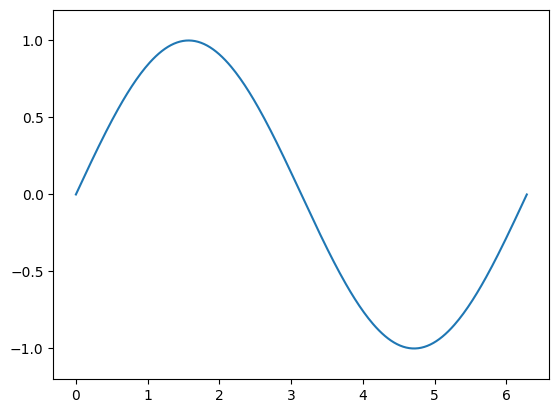

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Canvas
fig, ax = plt.subplots()
ax.set_ylim(-1.2, 1.2)

# First render
x=np.linspace(0, 2*np.pi, 300)
line, = ax.plot(x, np.sin(x))

def update(i):
    # consider i=t, so draw sin(x-t*omega)
    line.set_ydata(np.sin(x-i*0.1))
    return line,
ani = FuncAnimation(fig, update, frames=120, interval=33)

from IPython.display import HTML
HTML(ani.to_jshtml())

### Traveling wave

only the updat e function changed, another way to write it   
but it's nearly the same???

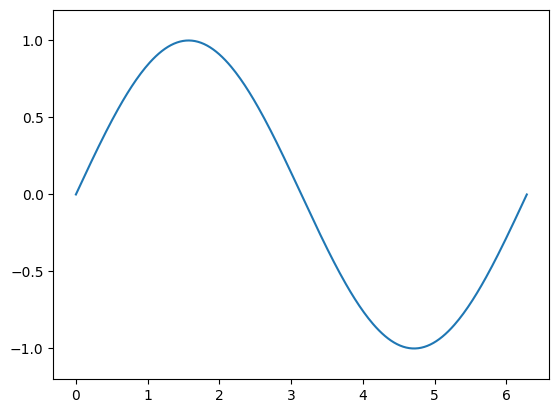

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

x=np.linspace(0, 2*np.pi, 300)
fig, ax = plt.subplots()
line, = ax.plot(x, np.sin(x))
ax.set_ylim(-1.2, 1.2)

def update(frame):
    t = frame/30
    y=np.sin(x-t)
    line.set_ydata(y)
    return line,
ani = FuncAnimation(fig, update, frames=120, interval=33)

from IPython.display import HTML
HTML(ani.to_jshtml())

### Animate bars

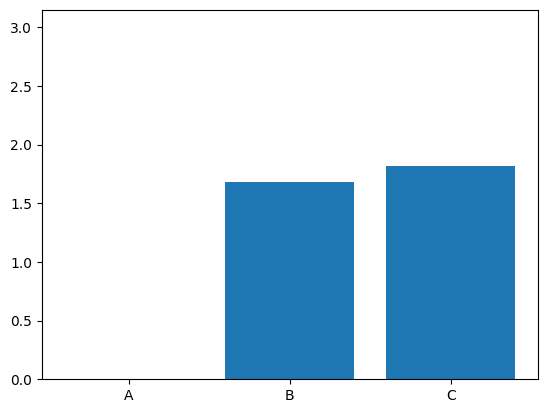

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Setup
fig, ax = plt.subplots()
bars = ax.bar(["A", "B", "C"], [1,2,3])


def update(i):
    values= 2*np.sin(i*0.1+np.arange(3))
    for bar, h in zip(bars,values):
        bar.set_height(h)
    return(tuple(bars))

ani = FuncAnimation(fig, update, frames=120, interval=33)

from IPython.display import HTML
HTML(ani.to_jshtml())

### Animate particle and scatter plot

**Explanation**

1- define the model  
write y(t)  
t = ...  
y = ...   

2- update code  
reveal the signal progressively, by updating the line data each frame  
in the other cases, i deleted the previous signal, now add more parts  


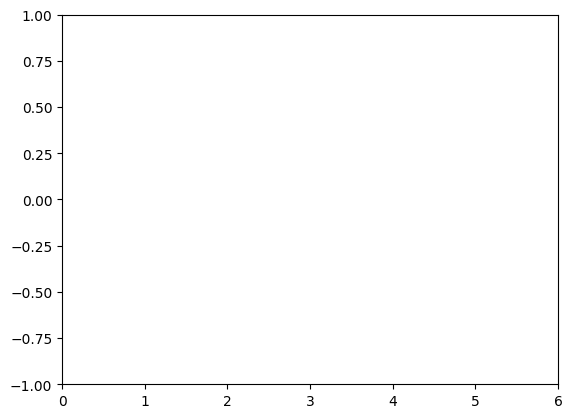

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Setup
fig, ax = plt.subplots()
ax.set_ylim(-1, 1)
ax.set_xlim(0,6)

# First render
line, = ax.plot(0,0)


t=np.linspace(0,6,181)
y = np.exp(-0.3*t)*np.sin(2*np.pi*t)


def update(i):
    line.set_data(t[:i+1], y[:i+1])
    return line,

ani = FuncAnimation(fig, update, frames=120, interval=33)

from IPython.display import HTML
HTML(ani.to_jshtml())

### Engineering animation

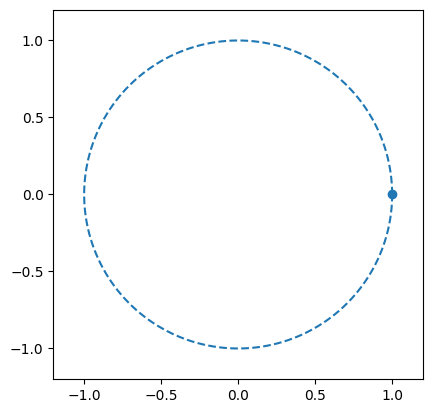

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Setup
fig, ax = plt.subplots()
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal")   # equal scaling on axes, to have circle, not ellypse
theta0 = np.linspace(0, 2* np.pi, 360)
ax.plot(np.cos(theta0), np.sin(theta0), linestyle='dashed')  # draw a circle

# First render
points = ax.scatter([1], [0])

def update(frame):
    line.set:data()
    theta = frame * 0.05   # angle of particle in current frame
    xy = np.array([[np.cos(theta),
                    np.sin(theta)]])    # plot the particle in the orrect position in the circle
    points.set_offsets(xy)   #  bc set_offsets will expect hape (N,2), update the scatter plot
    return points,

ani = FuncAnimation(fig, update, frames=120, interval=33)

from IPython.display import HTML
HTML(ani.to_jshtml())

### Save it

In [ ]:
# Save it

# as GIF or MP4
from matplotlib.animation import PillowWriter
ani.save("wave.gif", writer=PilloeWriter(fps=30))
ani.save("wave.mp4", writer=ffmpeg, fps=30)

# Display on Jupyter notebook
from IPython.display import HTML
HTML(ani.to_jshtml())
# if use this, omit plt.show() at the end